In [ ]:
from src.gaussian_mixture import GaussianMixtureMAR
from src.motivating_example import MotivatingExample
from src.data_generator import DataGenerator
from src.ampute_mar import AmputeMAR

import numpy as np
import pandas as pd
import torch

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

from collections.abc import Callable
from typing import Optional

from joblib import Parallel, delayed

In [ ]:
class RegressionMAR(GaussianMixtureMAR, AmputeMAR):

    def __init__(self,
                 data_generator,
                 n,
                 d,
                 patterns,
                 Ycol,
                 k_range,
                 criterion="bic",
                 cov_type= 'diag', #'uni_diag',
                 max_iter=100,
                 tol=0.000001,
                 eps=0.000001,
                 reg_covar=0.000001,
                 n_init=20,
                 _k_tol=1,
                 device="cpu",
                 verbose=False,
                 prop=None):
        super().__init__(k_range, criterion, cov_type, max_iter, tol, eps,
                         reg_covar, n_init, _k_tol, device, verbose)
        self.n = n
        self.d = d
        self.Ycol = Ycol
        self.XY = data_generator.sample_truth(n, d)
        self.XYna, self.M = self.ampute(self.XY, patterns=patterns, prop=prop)
        self.model = self.fit(self.XYna, self.M)

    def linear_regression(self, method="generation"):
        if method == "generation":
            XYtilde = self.model.sample(self.n)[0]
        elif method == "imputation":
            XYtilde = self.model.impute(self.XYna, self.M)
        elif method == "complete":
            XYtilde = self.XY
        elif method == "nmmipw":
            #=== FOR NMMIPW ===#
            import rpy2.robjects as ro
            from rpy2.robjects import pandas2ri, numpy2ri
            from rpy2.robjects.conversion import localconverter
            from rpy2.robjects.packages import importr
            nmm = importr("NMMIPW")
            
            ro.r('''
            predict_prop <- function(ps, newdata, pattern) {
              X <- as.matrix(newdata); M <- nrow(pattern)
              work_df <- c(); selection <- c(0)
              for (m in 2:M) {
                work_df <- cbind(work_df, cbind(1, X[, pattern[m, ] == 1]))
                selection <- c(selection, sum(pattern[m, ]) + 1)
              }
              selection <- cumsum(selection)
              NMMIPW:::prop_compute(para = ps$gamma_para, work_df = work_df,
                                    R = rep(1, nrow(X)), selection = selection,
                                    sigma_star = ps$sigma_star, pattern = pattern)
            }
            ''')
            predict_prop = ro.r["predict_prop"]
            #==================#
            
            # compute IPW estimator based on NMMIPW R package
            with localconverter(ro.default_converter + pandas2ri.converter + numpy2ri.converter):
                r_X = ro.conversion.py2rpy(self.XYna.detach().numpy())
                r_O = ro.conversion.py2rpy(self.M.detach().numpy().astype(np.int32))
            pre = nmm.nmm_preprocessing(r_X, r_O)
            ps = nmm.PS(r_X, pre.rx2("R"), pre.rx2("pattern"))
            ipw = np.asarray(ps.rx2("prop"))
            
            # set negative values to small positive value
            ipw[ipw < 0] = 0.01

            # extract fully observed rows and fit weighted regression
            idx_m0 = self.M.sum(dim=1)==self.d
            Xm0 = self.XYna[idx_m0][:, np.arange(self.XYna.shape[1]) != self.Ycol % self.XYna.shape[1]]
            Ym0 = self.XYna[idx_m0][:, self.Ycol]
            lin_reg = LinearRegression().fit(Xm0, Ym0, sample_weight=1/ipw)
            return lin_reg
        else:
            raise NotImplementedError("method argument needs to be 'generation', 'imputation' or 'complete'")

        Xtilde = XYtilde[:, np.arange(XYtilde.shape[1]) != self.Ycol % XYtilde.shape[1]]
        Ytilde = XYtilde[:, self.Ycol]
        
        lin_reg = LinearRegression().fit(Xtilde, Ytilde)
        return lin_reg

In [ ]:
class DataGeneratorXY():
    def __init__(
        self,
        coef_true: torch.tensor,
        sample_error: Callable[[int], torch.tensor],
        data_generator_X: DataGenerator
    ):
        self.sample_X = data_generator_X.sample_truth
        self.sample_error = sample_error
        self.coef_true = coef_true

    def sample_truth(
        self,
        n:int,
        d:int
    ):
        # generate X based on DataGenerator
        X = self.sample_X(n, d-1)
        # generate Y as linear combination + error
        Y = self.coef_true[0] + X @ self.coef_true[1:] + self.sample_error(n)
        # concatenate X and Y
        # (Y in first column because ampute function keeps last column fully observed)
        return torch.cat([Y[:, None], X], dim=1)
        

In [ ]:
def run_experiment(data_generator, n, d, Ycol, B, k_range = (1,100)):
    # create a new column for Y which really follows a linear regression of the other variables
    if Ycol == "new":
        coef_true = torch.tensor(np.random.choice([0, 0.5, -0.5, 2, -2], size=d+1)) #d+1 because of intercept
        dg = DataGeneratorXY(coef_true=coef_true, sample_error=lambda n: np.sqrt(0.5)*torch.randn(n), data_generator_X=data_generator)
        Ycol = 0
        d_eff = d + 1
    # otherwise we regress one of the X columns (Ycol) given all others 
    elif type(Ycol) == int and Ycol not in range(d):
        coef_true = None
        dg = data_generator
        d_eff = d
    else:
        raise ValueError("Ycol needs to be set to 'new' or an integer between -d (counting backwards) and d")

    # use same test data for all replications
    test_data = dg.sample_truth(n, d_eff)
    Xtest = test_data[:, np.arange(test_data.shape[1]) != Ycol % test_data.shape[1]]
    Ytest = test_data[:, Ycol] 

    # use same pattern for all replications (make sure that Ycol is sometimes missing but not always)
    rng = np.random.default_rng(123)
    while True:
        patterns = AmputeMAR.sample_patterns(d_eff, n, rng)
        if (patterns[:, Ycol] == 0).any() and (patterns[:, Ycol] == 1).any():
            break

    # variables to save results in
    methods = ['generation', 'imputation', 'complete', 'nmmipw']
    coef_est = {m: [] for m in methods}
    mse = {m: [] for m in methods}

    # worker function to run in parallel
    def one_run(i, seed=0):
        # set seed explicitly to ensure reproducibility
        np.random.seed(seed + i)
        torch.manual_seed(seed + i)
    
        regr = RegressionMAR(dg, n, d_eff, patterns, Ycol, k_range)
        out = {}
        for method in methods:
            lin_reg = regr.linear_regression(method=method)
            coef = np.concatenate(([lin_reg.intercept_], lin_reg.coef_))
            err = mean_squared_error(lin_reg.predict(Xtest), Ytest)
            out[method] = (coef, err)
        return out
        
    results = Parallel(n_jobs=-1)(delayed(one_run)(i) for i in range(B))
    
    coef_est = {m: [r[m][0] for r in results] for m in methods}
    mse      = {m: [r[m][1] for r in results] for m in methods}

    # # run sequentially
    # for i in range(B):
    #     regr = RegressionMAR(dg, n, d_eff, patterns, Ycol, k_range)
    #     for method in methods:
    #         lin_reg = regr.linear_regression(method=method)
    #         coef_est[method].append(np.concatenate(([lin_reg.intercept_], lin_reg.coef_)))
    #         mse[method].append(mean_squared_error(lin_reg.predict(Xtest), Ytest))
    
    return coef_est, mse, patterns, coef_true

In [ ]:
def plot_coefficient_boxplots(results, coef_names=None, coef=None, coef_label="True value",
                              coef_color="black", ncols=3, ax_size=(4.2, 3.4),
                              show_points=False, save_path=None):
    """
    results:     dict {method: [array_run1, array_run2, ...]}, each array holds the coefficient estimates
    coef_names:  optional list of labels for the coefficients (default: "Coef 0", "Coef 1", ...)
    coef:        optional array (one value per coefficient); coef[j] is drawn as a horizontal
                 dashed line in panel j
    coef_label:  legend label for that line
    coef_color:  color of that line
    show_points: overlay the individual runs (recommended when there are few runs per method)
    """
    methods = list(results.keys())
    data = {m: np.vstack(results[m]) for m in methods}          # (n_runs, n_coefs) per method
    n_coefs = data[methods[0]].shape[1]
    if coef_names is None:
        coef_names = [f"Coef {j}" for j in range(n_coefs)]
 
    if coef is not None:
        coef = np.asarray(coef, dtype=float).ravel()
        if len(coef) != n_coefs:
            raise ValueError(f"coef has {len(coef)} values but the results have {n_coefs} coefficients.")
 
    nrows = int(np.ceil(n_coefs / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ax_size[0] * ncols, ax_size[1] * nrows),
                             squeeze=False)
    axes_flat = axes.ravel()
    rng = np.random.default_rng(0)
    colors = plt.cm.tab10(np.arange(len(methods)) % 10)
    # colors = ['#ff7f0e'] + ['#4C72B0'] * (len(methods)-1) 
 
    for j in range(n_coefs):
        ax = axes_flat[j]
        vals = [data[m][:, j] for m in methods]
        bp = ax.boxplot(vals, positions=np.arange(1, len(methods) + 1), widths=0.6,
                        patch_artist=True, medianprops=dict(color="black"), showfliers=False)
        for patch, c in zip(bp["boxes"], colors):
            patch.set_facecolor(c)
            # patch.set_alpha(0.45)
 
        if show_points:
            for i, v in enumerate(vals, start=1):
                ax.scatter(i + rng.uniform(-0.12, 0.12, size=len(v)), v,
                           s=14, color="black", zorder=3, alpha=0.8)
 
        if coef is not None:
            ax.axhline(coef[j], color=coef_color, linestyle="--", linewidth=1.2,
                       label=coef_label, zorder=2)
 
        ax.axhline(0, color="gray", linewidth=0.5, zorder=0)
        ax.set_title(coef_names[j])
        ax.set_xticks(np.arange(1, len(methods) + 1))
        ax.set_xticklabels(methods)#, rotation=45, ha="right")
        ax.grid(axis="y", alpha=0.3)
 
    if coef is not None:
        axes_flat[0].legend(loc="best", fontsize=8)
 
    for ax in axes_flat[n_coefs:]:       # hide unused panels
        ax.set_visible(False)
 
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig, axes

In [ ]:
n = 2000
d = 10
data_generator = DataGenerator(distr='Logistic')
Ycol = 'new'
B = 10

coef_est, mse, patterns, coef_true = run_experiment(data_generator, n, d, Ycol, B)

In [8]:
# print("Average probability for each column to be observed (if not fully observed)")
# for i, col_prob in enumerate(patterns.mean(axis=0)):
#     if i == 0:
#         print(f"Y: {col_prob:.2f}")
#     else:
#         print(f"X{i}: {col_prob:.2f}")
print(patterns)

[[1 1 0 1 0 1]
 [0 0 0 0 0 1]
 [1 0 1 0 0 1]]


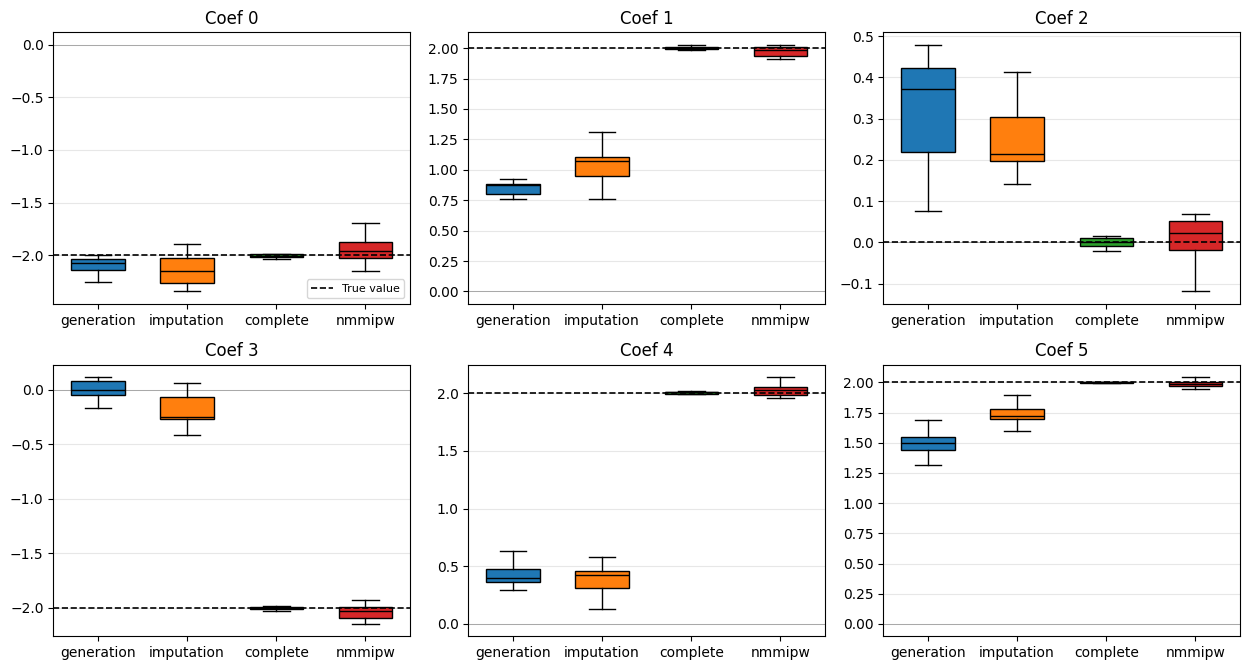

In [9]:
plot_coefficient_boxplots(coef_est, coef=coef_true)
plt.savefig("coef.png")

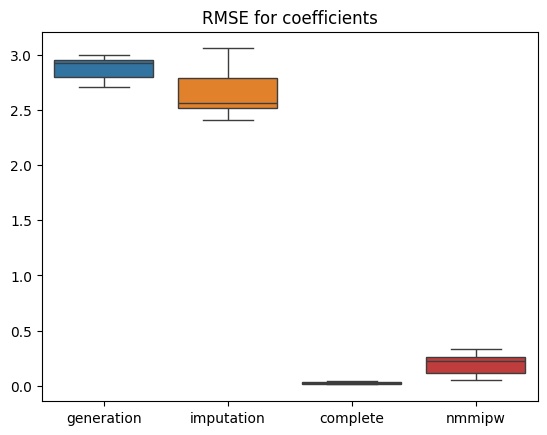

In [10]:
coef_true_np = coef_true.detach().numpy()
rmse_coef = pd.DataFrame({method: [np.linalg.norm(c - coef_true_np) for c in coefs] for method, coefs in coef_est.items()})
sns.boxplot(rmse_coef, showfliers=False)
plt.title("RMSE for coefficients")
plt.savefig("rmse_coef.png")

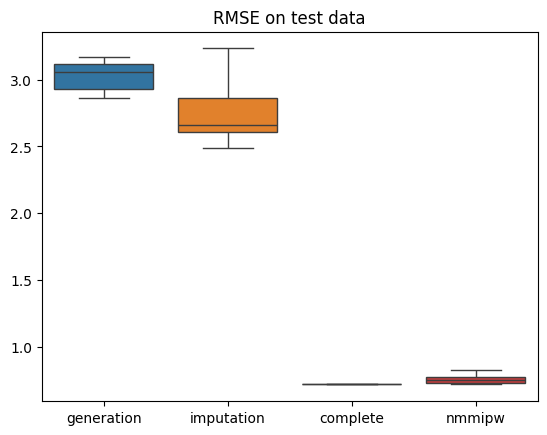

In [11]:
rmse = np.sqrt(pd.DataFrame(mse))
sns.boxplot(rmse, showfliers=False)
plt.title("RMSE on test data")
plt.savefig("rmse.png")